In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from io import StringIO

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

def create_sample_data():
   
    
    # 读取数据
    df = pd.read_csv('result.csv')
    
    # 处理空值
    barrier_columns = [col for col in df.columns if col.startswith('barrier_')]
    df[barrier_columns] = df[barrier_columns].fillna(0)
    
    return df

def calculate_barrier_ratios(df):
    """
    计算每行barrier列的总和以及占total_cycle的比例
    
    参数:
        df: DataFrame，包含code, total_cycle和barrier列
    
    返回:
        包含比例计算的DataFrame
    """
    # 识别barrier列
    barrier_columns = [col for col in df.columns if col.startswith('barrier_')]
    
    # 计算每行barrier的总和
    df['barrier_total'] = df[barrier_columns].sum(axis=1)
    
    # 计算barrier占total_cycle的比例
    df['barrier_ratio'] = df['barrier_total'] / df['total_cycle']
    
    # 计算非barrier部分的比例
    df['non_barrier_ratio'] = 1 - df['barrier_ratio']
    
    # 限制比例在0-1之间（防止数据异常）
    df['barrier_ratio'] = df['barrier_ratio'].clip(0, 1)
    df['non_barrier_ratio'] = df['non_barrier_ratio'].clip(0, 1)
    
    return df

def create_stacked_bar_chart(df, figsize=(12, 8)):
    """
    创建堆叠柱状图
    
    参数:
        df: 包含分析数据的DataFrame
        figsize: 图形大小
    """
    # 排序数据（按code排序）
    df_sorted = df.sort_values('code').reset_index(drop=True)
    
    # 创建图形
    fig, ax = plt.subplots(figsize=figsize)
    
    # 设置柱状图参数
    codes = df_sorted['code'].astype(str)
    total_cycles = df_sorted['total_cycle']
    barrier_ratios = df_sorted['barrier_ratio']
    non_barrier_ratios = df_sorted['non_barrier_ratio']
    
    # 计算柱状图的高度（实际的周期数）
    barrier_heights = total_cycles * barrier_ratios
    non_barrier_heights = total_cycles * non_barrier_ratios
    
    # 绘制堆叠柱状图
    width = 0.6
    x_pos = np.arange(len(codes))
    
    # 蓝色部分（非barrier）
    bars1 = ax.bar(x_pos, non_barrier_heights, width, 
                   label='Non-barrier Cycles', color='skyblue', alpha=0.8)
    
    # 红色部分（barrier）
    bars2 = ax.bar(x_pos, barrier_heights, width, 
                   bottom=non_barrier_heights, 
                   label='Barrier Cycles', color='red', alpha=0.8)
    
    # 设置图形属性
    ax.set_xlabel('Code', fontsize=12, fontweight='bold')
    ax.set_ylabel('Total Cycles', fontsize=12, fontweight='bold')
    ax.set_title('Barrier vs Non-barrier Cycles Distribution', fontsize=14, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(codes)
    
    # 添加图例
    ax.legend(loc='upper right')
    
    # 添加网格
    ax.grid(True, alpha=0.3, axis='y')
    
    # 在每个柱上添加比例标签
    for i, (code, barrier_ratio, total_cycle) in enumerate(zip(codes, barrier_ratios, total_cycles)):
        # 添加barrier比例标签
        if barrier_ratio > 0.05:  # 只在比例大于5%时显示
            ax.text(i, total_cycle * (1 - barrier_ratio/2), 
                   f'{barrier_ratio:.1%}', 
                   ha='center', va='center', fontweight='bold', color='white')
    
    # 调整布局
    plt.tight_layout()
    
    return fig, ax

def create_percentage_bar_chart(df, figsize=(12, 6)):
    """
    创建百分比柱状图（每个柱高度为100%）
    
    参数:
        df: 包含分析数据的DataFrame
        figsize: 图形大小
    """
    # 排序数据
    df_sorted = df.sort_values('code').reset_index(drop=True)
    
    # 创建图形
    fig, ax = plt.subplots(figsize=figsize)
    
    codes = df_sorted['code'].astype(str)
    barrier_ratios = df_sorted['barrier_ratio']
    non_barrier_ratios = df_sorted['non_barrier_ratio']
    
    # 绘制百分比堆叠柱状图
    width = 0.6
    x_pos = np.arange(len(codes))
    
    # 蓝色部分（非barrier）
    bars1 = ax.bar(x_pos, non_barrier_ratios, width, 
                   label='Non-barrier (%)', color='skyblue', alpha=0.8)
    
    # 红色部分（barrier）
    bars2 = ax.bar(x_pos, barrier_ratios, width, 
                   bottom=non_barrier_ratios, 
                   label='Barrier (%)', color='red', alpha=0.8)
    
    # 设置图形属性
    ax.set_xlabel('Code', fontsize=12, fontweight='bold')
    ax.set_ylabel('Percentage', fontsize=12, fontweight='bold')
    ax.set_title('Barrier vs Non-barrier Percentage Distribution', fontsize=14, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(codes)
    ax.set_ylim(0, 1)
    
    # 设置y轴为百分比格式
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    
    # 添加图例
    ax.legend(loc='upper right')
    
    # 添加网格
    ax.grid(True, alpha=0.3, axis='y')
    
    # 在每个柱上添加具体百分比
    for i, (code, barrier_ratio) in enumerate(zip(codes, barrier_ratios)):
        if barrier_ratio > 0.05:  # 只在比例大于5%时显示
            ax.text(i, 1 - barrier_ratio/2, 
                   f'{barrier_ratio:.1%}', 
                   ha='center', va='center', fontweight='bold', color='white')
    
    plt.tight_layout()
    
    return fig, ax





def main():
    """
    主函数 - 执行完整的分析和可视化
    """
    print("=== Barrier数据分析和可视化 ===")
    
    # 1. 创建或加载数据
    df = create_sample_data()
    print(f"数据加载完成，共 {len(df)} 行")
    
    # 2. 计算barrier比例
    df = calculate_barrier_ratios(df)
    print("barrier比例计算完成")
    

    # 4. 创建可视化图表
    print("\n=== 生成可视化图表 ===")
    
    # 创建绝对数量的堆叠柱状图
    fig1, ax1 = create_stacked_bar_chart(df, figsize=(14, 8))
    fig1.savefig('barrier.png', dpi=300, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    print("图表已保存为: barrier.png")
    plt.show()
    
    # # 创建百分比堆叠柱状图
    # fig2, ax2 = create_percentage_bar_chart(df, figsize=(14, 6))
    # plt.show()
    
    
    return df


if __name__ == "__main__":
    # 运行主分析
    df_result = main()
    
    # 如果你有自己的CSV文件，可以这样分析：
    # df_custom = analyze_custom_data("your_data.csv")

=== Baseline时间成本分析 (使用 x - x_ 计算) ===
数据加载完成，共 10 个baseline
时间计算完成 (使用 x - x_ 方式)

=== 生成可视化图表 ===
总时间图表已保存为: baseline_total_time.png


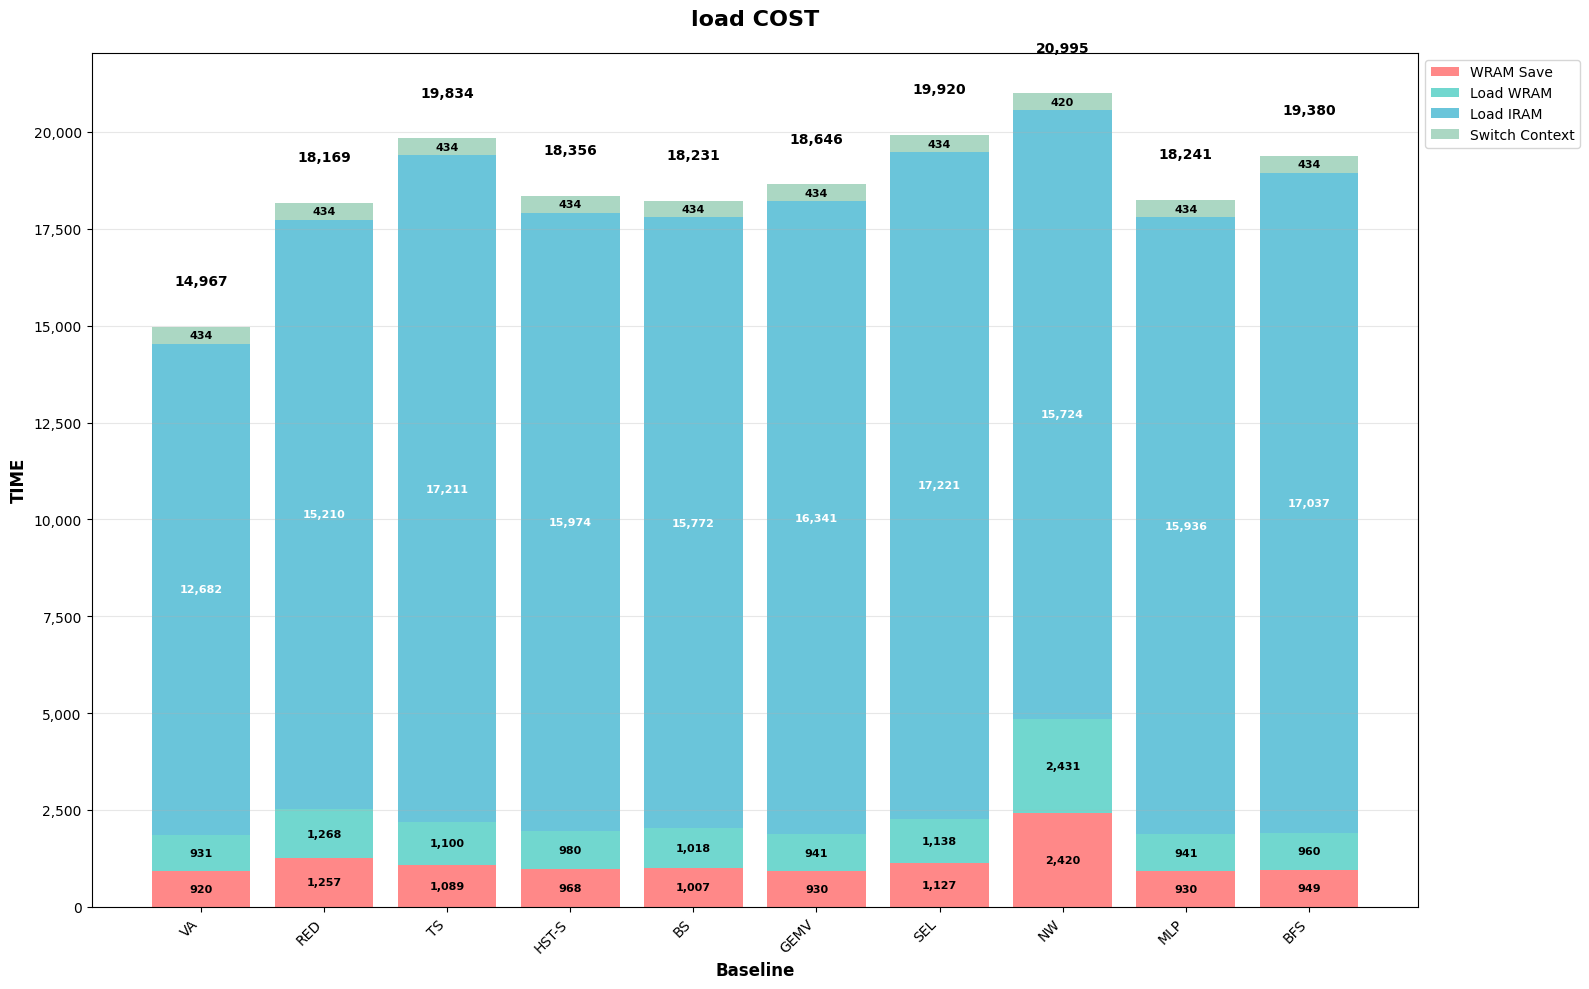

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

# 设置中文字体支持和样式
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.style.use('default')

def create_baseline_data():
   
    
    # 读取数据
    df = pd.read_csv("init.csv")
    
    return df

def calculate_baseline_costs(df):
    """
    计算每个baseline的总花费和各项花费占比
    使用 x - x_ 的方式计算每个项目的实际时间
    
    参数:
        df: 原始DataFrame
    
    返回:
        包含计算结果的DataFrame
    """
    # 定义四个项目的时间计算（使用 x - x_ 的方式）
    project_calculations = {
        'wram_save_time': ('wram_save', 'wram_save_'),
        'load_wram_time': ('load_wram', 'load_wram_'),
        'load_iram_time': ('load_iram', 'load_iram_'),
        'switch_context_time': ('switch_context', 'switch_context_')
    }
    
    # 计算每个项目的实际时间
    for time_col, (start_col, end_col) in project_calculations.items():
        df[time_col] = df[start_col] - df[end_col]
    
    # 定义四个项目的列名（计算后的时间列）
    project_columns = ['wram_save_time', 'load_wram_time', 'load_iram_time', 'switch_context_time']
    
    # 计算每个baseline的四个项目总花费
    df['total_cost'] = df[project_columns].sum(axis=1)
    
    # 计算各项花费的占比
    for col in project_columns:
        df[f'{col}_ratio'] = df[col] / df['total_cost']
    
    # 添加项目名称映射
    project_names = {
        'wram_save_time': 'WRAM Save',
        'load_wram_time': 'Load WRAM', 
        'load_iram_time': 'Load IRAM',
        'switch_context_time': 'Switch Context'
    }
    
    return df, project_columns, project_names

def create_total_cost_chart(df, project_columns, figsize=(14, 8)):
    """
    创建总花费的堆叠柱状图
    
    参数:
        df: DataFrame
        project_columns: 项目列名列表
        figsize: 图形大小
    """
    # 准备数据
    baselines = df['baseline'].tolist()
    
    # 设置颜色
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
    project_names = ['WRAM Save', 'Load WRAM', 'Load IRAM', 'Switch Context']
    
    # 创建图形
    fig, ax = plt.subplots(figsize=figsize)
    
    # 创建堆叠柱状图
    bottom = np.zeros(len(baselines))
    
    for i, col in enumerate(project_columns):
        values = df[col].values
        bars = ax.bar(baselines, values, bottom=bottom, 
                     label=project_names[i], color=colors[i], alpha=0.8)
        
        # 在每个分段中间添加数值标签
        for j, (bar, value) in enumerate(zip(bars, values)):
            if value > 0:  # 只在值大于0时添加标签
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2, 
                       bottom[j] + height/2,
                       f'{value:,.0f}', 
                       ha='center', va='center', 
                       fontsize=8, fontweight='bold',
                       color='white' if height > 5000 else 'black')
        
        bottom += values
    
    # 在每个柱子顶部添加总计
    for i, (baseline, total) in enumerate(zip(baselines, df['total_cost'])):
        ax.text(i, total + 1000, f'{total:,.0f}', 
               ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # 设置图形属性
    ax.set_title('load COST' , fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Baseline', fontsize=12, fontweight='bold')
    ax.set_ylabel('TIME', fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    
    # 设置y轴格式
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'))
    
    # 旋转x轴标签
    plt.xticks(rotation=45, ha='right')
    
    # 添加网格
    ax.grid(True, alpha=0.3, axis='y')
    
    # 调整布局
    plt.tight_layout()
    
    return fig, ax

def create_percentage_chart(df, project_columns, figsize=(14, 8)):
    """
    创建各项花费占比的堆叠柱状图
    
    参数:
        df: DataFrame
        project_columns: 项目列名列表
        figsize: 图形大小
    """
    # 准备数据
    baselines = df['baseline'].tolist()
    ratio_columns = [f'{col}_ratio' for col in project_columns]
    
    # 设置颜色
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
    project_names = ['WRAM Save', 'Load WRAM', 'Load IRAM', 'Switch Context']
    
    # 创建图形
    fig, ax = plt.subplots(figsize=figsize)
    
    # 创建堆叠柱状图
    bottom = np.zeros(len(baselines))
    
    for i, (col, ratio_col) in enumerate(zip(project_columns, ratio_columns)):
        ratios = df[ratio_col].values
        values = df[col].values
        
        bars = ax.bar(baselines, ratios, bottom=bottom, 
                     label=project_names[i], color=colors[i], alpha=0.8)
        
        # 在每个分段中间添加百分比标签
        for j, (bar, ratio, value) in enumerate(zip(bars, ratios, values)):
            if ratio > 0.05:  # 只在占比大于5%时显示标签
                ax.text(bar.get_x() + bar.get_width()/2, 
                       bottom[j] + ratio/2,
                       f'{ratio:.1%}\n({value:,.0f})', 
                       ha='center', va='center', 
                       fontsize=8, fontweight='bold',
                       color='white' if ratio > 0.3 else 'black')
        
        bottom += ratios
    
    # 设置图形属性
    ax.set_title('各Baseline在四个项目上的时间占比 (x - x_)', fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Baseline', fontsize=12, fontweight='bold')
    ax.set_ylabel('占比', fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    
    # 设置y轴为百分比格式
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.set_ylim(0, 1)
    
    # 旋转x轴标签
    plt.xticks(rotation=45, ha='right')
    
    # 添加网格
    ax.grid(True, alpha=0.3, axis='y')
    
    # 调整布局
    plt.tight_layout()
    
    return fig, ax

def create_comparison_chart(df, project_columns, figsize=(16, 10)):
    """
    创建对比图表（分组柱状图）
    
    参数:
        df: DataFrame
        project_columns: 项目列名列表
        figsize: 图形大小
    """
    # 设置数据
    baselines = df['baseline'].tolist()
    project_names = ['WRAM Save', 'Load WRAM', 'Load IRAM', 'Switch Context']
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
    
    # 创建图形
    fig, ax = plt.subplots(figsize=figsize)
    
    # 设置柱状图参数
    x = np.arange(len(baselines))
    width = 0.2  # 柱子宽度
    
    # 为每个项目创建一组柱子
    for i, col in enumerate(project_columns):
        values = df[col].values
        offset = (i - 1.5) * width  # 居中对齐
        
        bars = ax.bar(x + offset, values, width, 
                     label=project_names[i], color=colors[i], alpha=0.8)
        
        # 在柱子上添加数值标签
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax.annotate(f'{height:,.0f}',
                           xy=(bar.get_x() + bar.get_width() / 2, height),
                           xytext=(0, 3),
                           textcoords="offset points",
                           ha='center', va='bottom', fontsize=8, rotation=90)
    
    # 设置图形属性
    ax.set_title('各Baseline在四个项目上的时间对比 (x - x_)', fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Baseline', fontsize=12, fontweight='bold')
    ax.set_ylabel('时间', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(baselines)
    ax.legend()
    
    # 设置y轴格式
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'))
    
    # 添加网格
    ax.grid(True, alpha=0.3, axis='y')
    
    # 调整布局
    plt.tight_layout()
    
    return fig, ax



def main():
    """
    主函数 - 执行完整的baseline分析
    """
    print("=== Baseline时间成本分析 (使用 x - x_ 计算) ===")
    
    # 1. 创建数据
    df = create_baseline_data()
    print(f"数据加载完成，共 {len(df)} 个baseline")
    
    # 2. 计算时间（使用 x - x_ 方式）和占比
    df, project_columns, project_names = calculate_baseline_costs(df)
    print("时间计算完成 (使用 x - x_ 方式)")
    
   
    
    # 4. 创建可视化图表
    print("\n=== 生成可视化图表 ===")
    
    # 总时间堆叠柱状图
    fig1, ax1 = create_total_cost_chart(df, project_columns, figsize=(16, 10))
    plt.savefig('baseline_total_time.png', dpi=300, bbox_inches='tight')
    print("总时间图表已保存为: baseline_total_time.png")
    plt.show()
    
    # # 占比堆叠柱状图
    # fig2, ax2 = create_percentage_chart(df, project_columns, figsize=(16, 10))
    # plt.savefig('baseline_time_percentage.png', dpi=300, bbox_inches='tight')
    # print("时间占比图表已保存为: baseline_time_percentage.png")
    # plt.show()
    
    # # 对比柱状图
    # fig3, ax3 = create_comparison_chart(df, project_columns, figsize=(18, 10))
    # plt.savefig('baseline_time_comparison.png', dpi=300, bbox_inches='tight')
    # print("时间对比图表已保存为: baseline_time_comparison.png")
    # plt.show()
    
   
    return df

def load_custom_baseline_data(csv_file):
    """
    加载自定义baseline数据
    
    参数:
        csv_file: CSV文件路径
    
    返回:
        DataFrame
    """
    try:
        df = pd.read_csv(csv_file)
        
        # 检查必要的列
        required_columns = ['baseline', 'wram_save', 'load_wram', 'load_iram', 'switch_context']
        missing_columns = [col for col in required_columns if col not in df.columns]
        
        if missing_columns:
            raise ValueError(f"CSV文件缺少必要的列: {missing_columns}")
        
        print(f"成功加载自定义数据: {len(df)} 个baseline")
        
        return df
        
    except Exception as e:
        print(f"加载自定义数据失败: {e}")
        return None

if __name__ == "__main__":
    # 运行主分析
    df_result = main()
    
    # 如果你有自己的CSV文件，可以这样分析：
    # df_custom = load_custom_baseline_data("your_baseline_data.csv")
    # if df_custom is not None:
    #     df_custom, project_columns, project_names = calculate_baseline_costs(df_custom)
    #     fig, ax = create_total_cost_chart(df_custom, project_columns)
    #     plt.show()